# Statistical Arbitrage — Pairs Trading & Cross-Sectional Residual Model

Workflow follows `.txt` in this directory. This notebook is built up phase by phase.

## Phase 0 — Setup

All tunable parameters live in this one cell and nowhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# --- Universe / data ---
DATA_START = "2018-01-01"
DATA_END = None  # None -> through today
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
PRICE_CACHE = DATA_DIR / f"prices_{DATA_START}.pkl"  # keyed by start date so changing it never serves stale data
MAX_MISSING_PCT = 0.05  # drop any ticker missing more than this fraction of trading days

# --- Walk-forward windows (trading days) ---
FORMATION_WINDOW = 252   # ~1 trading year: used to form pairs / estimate hedge ratios / fit factors
TRADING_WINDOW = 63      # ~1 trading quarter: traded out-of-sample before re-forming

# --- Cointegration (Phase 2) ---
ADF_SIGNIFICANCE = 0.05  # p-value threshold for the Engle-Granger ADF test

# --- Spread signal (Phase 3) ---
ENTRY_Z = 2.0
EXIT_Z = 0.0
STOP_Z = 3.0
MAX_HALF_LIVES_HELD = 2  # time stop: exit if a trade has been open longer than this many half-lives
MAX_HALF_LIFE_DAYS = 40  # Phase 7: discard names whose residual half-life exceeds this

# --- Portfolio construction ---
MAX_CONCURRENT_POSITIONS = 20  # Phase 1-6 pairs book
PAIR_LEG_WEIGHT = 1.0 / MAX_CONCURRENT_POSITIONS  # each leg of each pair; full book = 100% long / 100% short
MAX_NAME_WEIGHT = 0.02         # 2% single-name cap, Phase 7 cross-sectional book
RESIDUAL_VARIANCE_TARGET = 0.55  # PCA: keep components explaining ~this much variance
ZSCORE_REBALANCE_THRESHOLD = 0.5  # Phase 7: only rebalance if z-score moved more than this since entry

# --- Costs ---
COMMISSION_RATE = 0.0005       # 5 bps per trade, per leg
HALF_SPREAD = 0.0005           # 5 bps half bid-ask spread, charged on every weight change, per leg
BORROW_RATE_ANNUAL = 0.005     # 50 bps/year borrow cost on the short leg, accrued daily
TRADING_DAYS_PER_YEAR = 252

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## Phase 1 — Data

**Universe.** We don't have point-in-time S&P 500 membership, so per the workflow we use a fixed list instead of a live index screen. Rather than a literal "200 largest by market cap in 2008" cut (which would pull in names that later went bankrupt, merged, or renamed — Lehman, GM pre-2010, Wachovia, WTX/RTX, DOW's 2019 spinoff, etc., corrupting a clean 15-year series), we hand-pick ~95 large, liquid S&P 500 constituents that have traded continuously under the same ticker since before 2010, spread across all 11 GICS sectors. **This is a smaller, more curated universe than the spec's 200-name example, and it still introduces mild survivorship bias: every name here is a company that not only existed in 2010 but survived, intact and liquid, all the way to today** — exactly the kind of stock a mean-reversion strategy finds easy to trade in hindsight.\n
**Total return proxy.** True point-in-time total-return prices aren't freely available; instead we pull `yfinance` prices with `auto_adjust=True`, which adjusts historical Close for both splits and dividends. This is the standard practical stand-in for a total-return series and avoids the artificial dividend-drop divergences the workflow warns about.

In [2]:
# GICS sector -> tickers. Long-tenured (pre-2010 listing), liquid large caps only.
UNIVERSE = {
    "Energy": [
        "XOM", "CVX", "COP", "SLB", "EOG", "OXY", "MRO", "WMB", "VLO", "HES",
    ],
    "Materials": [
        "APD", "ECL", "NEM", "FCX", "NUE", "PPG", "IFF", "ALB", "MOS", "VMC",
    ],
    "Industrials": [
        "HON", "MMM", "GE", "CAT", "DE", "UNP", "UPS", "FDX", "LMT", "NOC",
        "BA", "EMR", "ITW", "CSX", "NSC", "WM", "GD", "ETN",
    ],
    "Consumer Discretionary": [
        "AMZN", "HD", "MCD", "NKE", "SBUX", "TJX", "LOW", "BKNG", "F", "TGT",
    ],
    "Consumer Staples": [
        "PG", "KO", "PEP", "WMT", "COST", "MO", "PM", "CL", "KMB", "GIS",
        "HSY", "STZ", "SYY", "KR",
    ],
    "Health Care": [
        "JNJ", "PFE", "MRK", "ABT", "UNH", "LLY", "BMY", "AMGN", "GILD", "MDT",
        "CVS", "CI", "SYK", "BDX",
    ],
    "Financials": [
        "JPM", "BAC", "WFC", "C", "GS", "MS", "USB", "PNC", "BK", "TRV",
        "AXP", "MET", "PRU", "AIG", "BLK", "SCHW", "CB", "AFL",
    ],
    "Information Technology": [
        "AAPL", "MSFT", "INTC", "CSCO", "ORCL", "IBM", "TXN", "QCOM", "ADP",
        "ADI", "HPQ", "MU", "KLAC", "ADSK", "PAYX",
    ],
    "Communication Services": [
        "T", "VZ", "CMCSA", "DIS", "OMC",
    ],
    "Utilities": [
        "NEE", "DUK", "SO", "D", "AEP", "EXC", "ED", "XEL", "WEC", "ES",
    ],
    "Real Estate": [
        "SPG", "PLD", "PSA", "O", "AVB", "EQR", "VTR",
    ],
}

TICKER_SECTOR = {t: sector for sector, tickers in UNIVERSE.items() for t in tickers}
TICKERS = sorted(TICKER_SECTOR)

assert len(TICKERS) == len(set(TICKERS)), "duplicate ticker across sectors"
print(f"Universe: {len(TICKERS)} tickers across {len(UNIVERSE)} GICS sectors")
for sector, tickers in UNIVERSE.items():
    print(f"  {sector:<24} {len(tickers)}")


Universe: 131 tickers across 11 GICS sectors
  Energy                   10
  Materials                10
  Industrials              18
  Consumer Discretionary   10
  Consumer Staples         14
  Health Care              14
  Financials               18
  Information Technology   15
  Communication Services   5
  Utilities                10
  Real Estate              7


In [3]:
import yfinance as yf


def load_prices(tickers, start, end, cache_path, force_reload=False):
    """Download daily adjusted close for `tickers`, cached to disk as a pickle."""
    if cache_path.exists() and not force_reload:
        return pd.read_pickle(cache_path)

    raw = yf.download(
        tickers, start=start, end=end,
        auto_adjust=True, progress=False, group_by="ticker", threads=True,
    )

    closes = {}
    for t in tickers:
        if t in raw.columns.get_level_values(0):
            closes[t] = raw[t]["Close"]
    prices = pd.concat(closes, axis=1).sort_index()

    # Yahoo's batch endpoint occasionally returns a truncated history. Never cache one.
    first = prices.index.min()
    if first > pd.Timestamp(start) + pd.Timedelta(days=14):
        raise RuntimeError(f"Download truncated: history starts {first.date()}, expected ~{start}. Re-run the cell.")

    prices.to_pickle(cache_path)
    return prices


prices = load_prices(TICKERS, DATA_START, DATA_END, PRICE_CACHE)
print(prices.shape)
prices.tail()


(2186, 131)


,AAPL,ABT,ADI,ADP,ADSK,AEP,AFL,AIG,ALB,AMGN,...,VMC,VTR,VZ,WEC,WFC,WM,WMB,WMT,XEL,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2026-09-08,316.220001,105.519997,363.200012,266.255981,212.210007,125.419998,115.160004,74.680000,129.134964,393.170013,...,258.299988,89.870003,50.410000,107.059998,87.959999,216.821747,75.283302,106.050003,76.879997,160.660004
2026-09-09,315.339996,105.230003,365.070007,263.533417,206.619995,124.669998,114.739998,75.029999,125.487244,391.269989,...,249.889999,89.379997,49.740002,106.150002,89.669998,215.487656,74.608208,105.830002,76.190002,164.229996
2026-09-10,326.570007,103.360001,361.250000,265.630005,211.610001,123.470001,114.470001,75.029999,121.699997,382.470001,...,250.600006,90.440002,49.970001,105.349998,89.449997,213.824997,72.294998,105.730003,75.410004,165.229996
2026-09-11,332.269989,101.949997,378.779999,268.260010,212.399994,123.330002,115.279999,75.330002,117.519997,377.350006,...,252.740005,89.989998,50.610001,105.330002,90.290001,213.460007,72.849998,107.150002,75.500000,165.990005
2026-09-14,335.029999,103.199997,363.079987,274.980011,228.589600,122.379997,116.269997,75.849998,115.080002,380.429993,...,251.585007,90.535004,51.395000,104.940002,88.294998,218.895096,71.870003,109.555000,74.870003,165.832001


In [4]:
# Data quality: drop tickers with excessive missing history (late IPOs, delistings,
# download failures), then forward-fill small gaps and drop any remaining NaN rows.
missing_pct = prices.isna().mean().sort_values(ascending=False)
print("Highest missing %:")
print(missing_pct.head(10))

keep = missing_pct[missing_pct <= MAX_MISSING_PCT].index
dropped = sorted(set(TICKERS) - set(keep))
print(f"\nDropping {len(dropped)} tickers with >{MAX_MISSING_PCT:.0%} missing data: {dropped}")

prices = prices[keep].ffill().dropna()
TICKER_SECTOR = {t: s for t, s in TICKER_SECTOR.items() if t in prices.columns}
TICKERS = list(prices.columns)

print(f"\nFinal universe: {len(TICKERS)} tickers")
print(f"Date range: {prices.index.min().date()} -> {prices.index.max().date()} ({len(prices)} trading days)")
prices.head()


Highest missing %:
BK      1.000000
MRO     1.000000
HES     1.000000
EQR     0.993596
AVB     0.987649
NSC     0.000000
NUE     0.000000
O       0.000000
OMC     0.000000
ORCL    0.000000
dtype: float64

Dropping 5 tickers with >5% missing data: ['AVB', 'BK', 'EQR', 'HES', 'MRO']

Final universe: 126 tickers
Date range: 2018-01-02 -> 2026-09-14 (2186 trading days)


,NSC,NUE,O,OMC,ORCL,NKE,OXY,PAYX,PEP,PFE,...,F,EXC,ETN,ES,EOG,EMR,ED,ECL,DUK,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-02,123.393585,55.692818,36.129063,53.611698,40.965111,55.829601,59.740486,51.335361,89.690918,23.040379,...,7.986330,20.788111,66.659904,46.715134,79.832092,57.751591,61.067394,122.845306,58.474350,57.811169
2018-01-03,123.401962,56.421219,36.033333,51.836212,41.913902,55.820808,60.564148,52.075150,89.455406,23.211094,...,8.049416,20.509811,69.009827,46.300873,81.022644,58.282261,60.490173,123.639915,58.291695,58.946564
2018-01-04,123.746208,56.278889,35.254894,52.351921,42.326820,55.785625,60.531845,52.563244,89.896034,23.261673,...,8.188196,20.221014,68.274406,45.649902,81.037224,58.363884,59.781445,124.644585,57.835026,59.028168
2018-01-05,126.172768,56.814716,35.229351,53.169670,42.581570,56.260468,60.200779,52.403107,90.154343,23.305935,...,8.326976,20.052992,68.798485,45.731270,81.928307,59.131294,59.723026,125.293106,57.568047,58.980583
2018-01-08,128.103943,57.132854,35.274002,53.346500,43.029629,56.761700,60.717602,52.075150,89.637733,23.046700,...,8.295439,20.268274,69.339485,46.049358,82.322708,58.943535,60.563240,124.854660,57.750725,59.245724


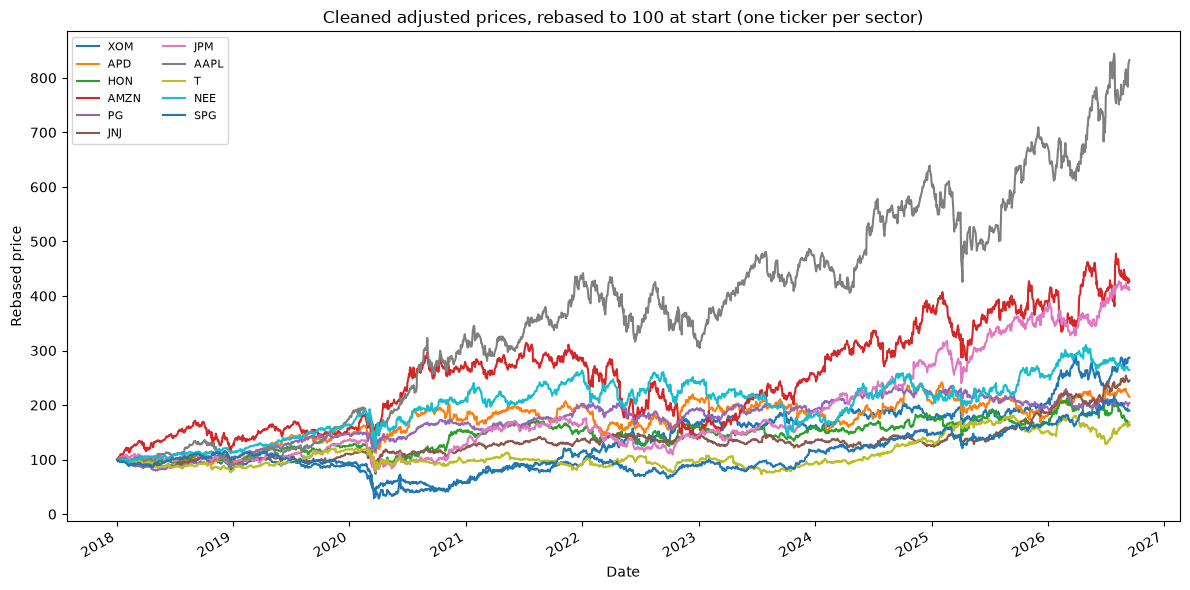

In [5]:
import matplotlib.pyplot as plt

# Plotting all 126 tickers would be an unreadable tangle, so show one representative
# ticker per GICS sector (the first listed name in each sector's list). Rebased to 100
# at the start of the sample so wildly different price levels (e.g. AMZN vs F) are
# comparable on one axis.
plot_tickers = []
for sector, tickers in UNIVERSE.items():
    for t in tickers:
        if t in prices.columns:
            plot_tickers.append(t)
            break

rebased = prices[plot_tickers] / prices[plot_tickers].iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 6))
rebased.plot(ax=ax)
ax.set_title("Cleaned adjusted prices, rebased to 100 at start (one ticker per sector)")
ax.set_ylabel("Rebased price")
ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


In [6]:
log_prices = np.log(prices)
log_prices.tail()


,NSC,NUE,O,OMC,ORCL,NKE,OXY,PAYX,PEP,PFE,...,F,EXC,ETN,ES,EOG,EMR,ED,ECL,DUK,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2026-09-08,5.792770,5.546739,4.111202,4.396053,5.090801,3.640214,4.100541,4.761575,4.930509,3.324676,...,2.639057,3.783053,6.045313,4.269558,4.979213,5.024867,4.684628,5.628017,4.797772,5.079290
2026-09-09,5.778581,5.552611,4.096176,4.360548,5.085310,3.620333,4.111202,4.742756,4.917716,3.324316,...,2.598979,3.777348,6.028809,4.254761,4.990501,5.012899,4.677398,5.606574,4.791069,5.101268
2026-09-10,5.778581,5.543066,4.087152,4.375128,5.030046,3.600595,4.113493,4.746496,4.917423,3.319626,...,2.630449,3.770229,6.014082,4.233962,4.993557,4.999709,4.670302,5.604330,4.782228,5.107338
2026-09-11,5.769164,5.558487,4.085976,4.369574,5.012500,3.605498,4.118387,4.751865,4.915005,3.322154,...,2.636912,3.764914,6.052959,4.227126,4.992879,5.025130,4.667769,5.621053,4.782647,5.111928
2026-09-14,5.768430,5.547577,4.086732,4.390986,4.965952,3.619395,4.133565,4.773266,4.917642,3.325935,...,2.629007,3.757356,5.979506,4.222738,5.011635,5.000383,4.665889,5.619966,4.780299,5.110975


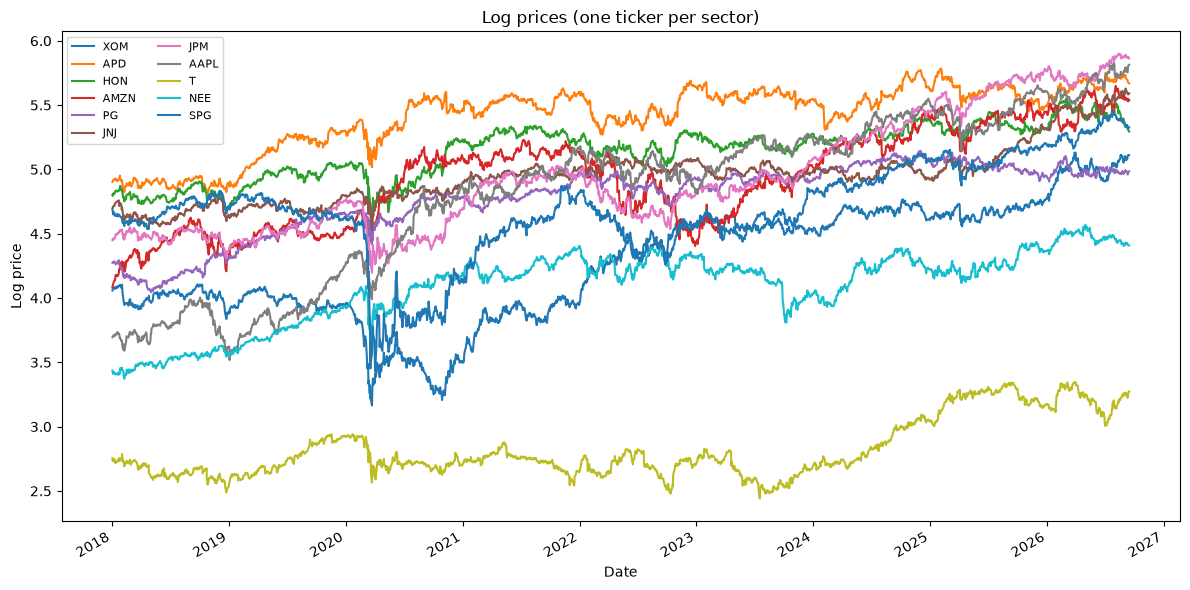

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
log_prices[plot_tickers].plot(ax=ax)
ax.set_title("Log prices (one ticker per sector)")
ax.set_ylabel("Log price")
ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


## Phase 2 — Pair formation (Engle-Granger)

For every pair of stocks in the same GICS sector, using only formation-window data:

1. OLS: `log(P_A) = α + β·log(P_B) + ε`. The slope β is the **hedge ratio**; it is saved and reused unchanged through the following trading window.
2. The residual ε is the **spread**.
3. **ADF test** on that residual. If p < `ADF_SIGNIFICANCE`, the spread is stationary (mean-reverting) and the pair is kept.

The hedge ratio and the ADF statistic come from the same regression — one step, not two.

Two caveats. Regression direction is not symmetric, so we fix one convention (alphabetical, A on B) rather than test both ways. And with several hundred candidate pairs per window, roughly `n_pairs × 5%` will pass the test by chance alone — the in-sample pass count is not evidence the strategy works; the out-of-sample walk-forward in Phase 5 is. Pairs with a negative hedge ratio are also dropped: a long/short pair only exists if the two names move in the same direction.

In [8]:
from itertools import combinations

from statsmodels.tsa.stattools import adfuller


def candidate_pairs(ticker_sector):
    """All unordered within-sector pairs, alphabetically ordered (a < b)."""
    by_sector = {}
    for t, s in ticker_sector.items():
        by_sector.setdefault(s, []).append(t)
    return [(a, b, s) for s, ts in by_sector.items() for a, b in combinations(sorted(ts), 2)]


def engle_granger(y, x):
    """OLS y = alpha + beta*x, then ADF on the residual. Returns (alpha, beta, spread, adf_stat, adf_pvalue)."""
    X = np.column_stack([np.ones(len(x)), x])
    (alpha, beta), *_ = np.linalg.lstsq(X, y, rcond=None)
    spread = y - (alpha + beta * x)
    adf_stat, pvalue, *_ = adfuller(spread, regression="c", autolag="AIC", result_object=False)
    return alpha, beta, spread, adf_stat, pvalue


def form_pairs(log_px, ticker_sector, significance=ADF_SIGNIFICANCE):
    """Run Engle-Granger on every within-sector pair over one formation window.

    Returns (selected, all_results): `selected` holds the cointegrated pairs sorted by p-value,
    `all_results` holds every candidate so the pass rate can be inspected.
    """
    rows = []
    for a, b, sector in candidate_pairs(ticker_sector):
        alpha, beta, _, adf_stat, pvalue = engle_granger(log_px[a].values, log_px[b].values)
        rows.append(dict(a=a, b=b, sector=sector, hedge_ratio=beta, intercept=alpha,
                         adf_stat=adf_stat, adf_pvalue=pvalue))
    all_results = pd.DataFrame(rows)
    selected = all_results[(all_results.adf_pvalue < significance) & (all_results.hedge_ratio > 0)]
    return selected.sort_values("adf_pvalue").reset_index(drop=True), all_results


In [9]:
# Demo on the first formation window. Phase 5 will roll this through the full history.
formation = log_prices.iloc[:FORMATION_WINDOW]
selected_pairs, all_pairs = form_pairs(formation, TICKER_SECTOR)

print(f"Formation window: {formation.index[0].date()} -> {formation.index[-1].date()} ({len(formation)} days)")
print(f"Candidate within-sector pairs: {len(all_pairs)}")
print(f"Cointegrated at {ADF_SIGNIFICANCE:.0%} (and hedge ratio > 0): {len(selected_pairs)}"
      f"   [expected by chance alone: ~{len(all_pairs) * ADF_SIGNIFICANCE:.0f}]")
print("\nSelected pairs by sector:")
print(selected_pairs.sector.value_counts().to_string())
selected_pairs.head(15)


Formation window: 2018-01-02 -> 2019-01-02 (252 days)
Candidate within-sector pairs: 759
Cointegrated at 5% (and hedge ratio > 0): 122   [expected by chance alone: ~38]

Selected pairs by sector:
sector
Financials                26
Industrials               24
Information Technology    16
Utilities                 14
Health Care               13
Materials                  8
Consumer Staples           8
Consumer Discretionary     6
Energy                     4
Communication Services     2
Real Estate                1


,a,b,sector,hedge_ratio,intercept,adf_stat,adf_pvalue
0,AEP,DUK,Utilities,1.004524,-0.106819,-4.492722,0.000203
1,FDX,GE,Industrials,0.346195,3.709251,-4.489090,0.000206
2,BA,HON,Industrials,0.691003,2.486543,-4.468755,0.000224
3,BA,EMR,Industrials,0.527125,3.659804,-4.402889,0.000293
4,AEP,XEL,Utilities,0.961566,0.504998,-4.354887,0.000356
5,ED,EXC,Utilities,0.249298,3.286150,-4.196504,0.000668
6,ED,NEE,Utilities,0.339627,2.865377,-4.112094,0.000925
7,BA,UPS,Industrials,0.219615,4.838624,-4.108811,0.000937
8,ED,ES,Utilities,0.411055,2.488336,-4.087679,0.001015
9,AMZN,NKE,Consumer Discretionary,1.307010,-1.040835,-4.061470,0.001121


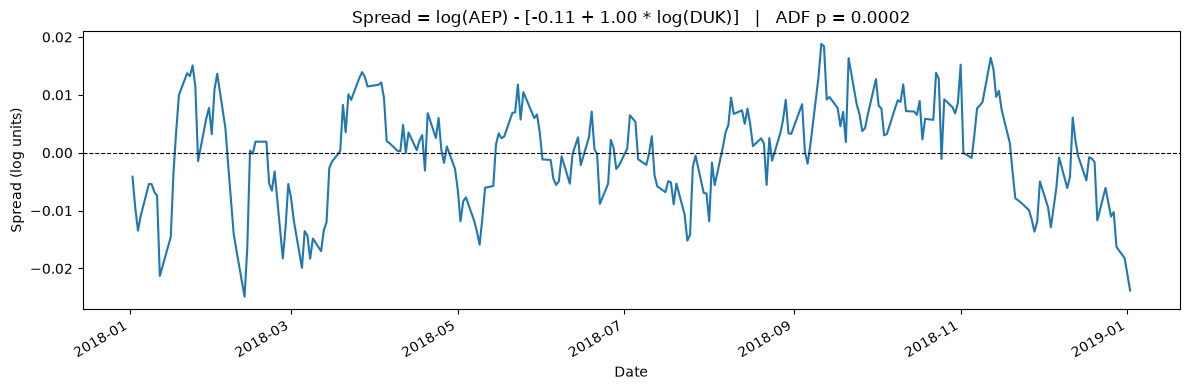

In [10]:
# The strongest pair's spread over the formation window.
top = selected_pairs.iloc[0]
_, _, spread, _, _ = engle_granger(formation[top.a].values, formation[top.b].values)
spread = pd.Series(spread, index=formation.index)

fig, ax = plt.subplots(figsize=(12, 4))
spread.plot(ax=ax)
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set_title(f"Spread = log({top.a}) - [{top.intercept:.2f} + {top.hedge_ratio:.2f} * log({top.b})]"
             f"   |   ADF p = {top.adf_pvalue:.4f}")
ax.set_ylabel("Spread (log units)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()


## Phase 3 — Spread signal

For each pair selected in Phase 2, everything is estimated on the **formation window only** and then frozen:

1. **Z-score.** Standardize the spread using the formation-window mean and standard deviation:
   `z_t = (ε_t - μ_form) / σ_form`. In the trading window the spread is recomputed with the
   frozen `α, β`, then standardized with the frozen `μ_form, σ_form`. Nothing is re-estimated
   out-of-sample — no rolling mean, no expanding window.

2. **Half-life.** Regress the daily change in the spread on its lagged level:
   `Δε_t = μ + γ·ε_{t-1} + u_t`. Mean reversion requires `γ < 0`; the half-life is
   `H = ln(2) / |γ|`, the number of days for a deviation to decay halfway. Pairs with `γ ≥ 0`
   or `H > MAX_HALF_LIFE_DAYS` are dropped — a spread that takes half a year to close ties up
   capital and will not survive costs.

**Trading rules.** Enter when `|z| ≥ ENTRY_Z` (long the spread if `z ≤ -2`, short if `z ≥ +2`).
Exit on mean reversion when `z` crosses `EXIT_Z = 0`. Stop out on `|z| ≥ STOP_Z = 3` (the
relationship is breaking) or after `MAX_HALF_LIVES_HELD × H` days (it isn't reverting on the
timescale we estimated).

Positions are the *target* held from the following day's open — Phase 4 lags them by one day
before applying prices, so a signal computed from day `t`'s close is never traded at day `t`'s close.

In [11]:
def spread_from_params(log_px, a, b, alpha, beta):
    """Spread for pair (a, b) using hedge ratio frozen in the formation window."""
    return log_px[a] - (alpha + beta * log_px[b])


def estimate_half_life(spread):
    """Regress d(spread) on lagged spread. Returns (gamma, half_life_days).

    gamma >= 0 means no mean reversion -> half-life is infinite.
    """
    s = np.asarray(spread, dtype=float)
    lagged = s[:-1]
    delta = np.diff(s)
    X = np.column_stack([np.ones(len(lagged)), lagged])
    (_, gamma), *_ = np.linalg.lstsq(X, delta, rcond=None)
    if gamma >= 0:
        return gamma, np.inf
    return gamma, np.log(2.0) / abs(gamma)


def fit_signal_params(log_px_form, a, b, alpha, beta):
    """Everything Phase 3 needs, estimated on the formation window and then frozen."""
    spread = spread_from_params(log_px_form, a, b, alpha, beta)
    gamma, hl = estimate_half_life(spread)
    return dict(
        mu=spread.mean(),
        sigma=spread.std(ddof=1),
        gamma=gamma,
        half_life=hl,
    )


def zscore(spread, mu, sigma):
    """Standardize with frozen formation-window moments — never with trading-window moments."""
    return (spread - mu) / sigma


def generate_positions(z, half_life,
                       entry=ENTRY_Z, exit_level=EXIT_Z, stop=STOP_Z,
                       max_half_lives=MAX_HALF_LIVES_HELD):
    """Path-dependent state machine over the trading window.

    Returns a Series in {-1, 0, +1}:
      +1 = long the spread  (long A, short beta*B) — entered when z <= -entry
      -1 = short the spread (short A, long beta*B) — entered when z >= +entry

    Exits, checked before any new entry on the same bar:
      - mean reversion: z crosses exit_level
      - z-stop:         |z| >= stop
      - time stop:      held longer than max_half_lives * half_life days

    After a stop-out, no new entry is allowed until |z| has come back inside the entry band.
    Without that, a stop at z = -3.5 exits and re-enters on the same bar, so neither stop
    ever actually reduces exposure.
    """
    max_hold = int(np.ceil(max_half_lives * half_life))
    state, days_held, cooldown = 0, 0, False
    out = np.zeros(len(z))

    for t, z_t in enumerate(z.to_numpy()):
        if state != 0:
            days_held += 1
            reverted = (state == 1 and z_t >= exit_level) or (state == -1 and z_t <= exit_level)
            stopped = abs(z_t) >= stop or days_held >= max_hold
            if reverted or stopped:
                state, days_held = 0, 0
                cooldown = stopped

        if cooldown and abs(z_t) < entry:
            cooldown = False

        if state == 0 and not cooldown:
            if z_t <= -entry:
                state, days_held = 1, 0
            elif z_t >= entry:
                state, days_held = -1, 0

        out[t] = state

    return pd.Series(out, index=z.index, name="position")


def build_pair_signal(log_px, pair_row, form_idx, trade_idx):
    """Fit on form_idx, generate positions on trade_idx. Returns None if the pair is untradable."""
    a, b = pair_row.a, pair_row.b
    params = fit_signal_params(log_px.loc[form_idx], a, b, pair_row.intercept, pair_row.hedge_ratio)

    if not np.isfinite(params["half_life"]) or params["half_life"] > MAX_HALF_LIFE_DAYS:
        return None
    if params["sigma"] <= 0:
        return None

    spread_trade = spread_from_params(log_px.loc[trade_idx], a, b,
                                      pair_row.intercept, pair_row.hedge_ratio)
    z_trade = zscore(spread_trade, params["mu"], params["sigma"])
    positions = generate_positions(z_trade, params["half_life"])

    return dict(a=a, b=b, sector=pair_row.sector,
                hedge_ratio=pair_row.hedge_ratio, intercept=pair_row.intercept,
                **params, z=z_trade, positions=positions)

In [12]:
# Same first formation window as Phase 2, traded on the next TRADING_WINDOW days.
form_idx = log_prices.index[:FORMATION_WINDOW]
trade_idx = log_prices.index[FORMATION_WINDOW:FORMATION_WINDOW + TRADING_WINDOW]

signals = [s for s in (build_pair_signal(log_prices, row, form_idx, trade_idx)
                       for row in selected_pairs.itertuples())
           if s is not None]

hl_table = pd.DataFrame([{k: s[k] for k in ("a", "b", "sector", "half_life", "sigma")}
                         for s in signals]).sort_values("half_life")

print(f"Pairs from Phase 2:                {len(selected_pairs)}")
print(f"Tradable after half-life filter:   {len(signals)}"
      f"   (dropped {len(selected_pairs) - len(signals)} with HL > {MAX_HALF_LIFE_DAYS}d or no reversion)")
print(f"Median half-life: {hl_table.half_life.median():.1f} days")
print(f"Trading window:   {trade_idx[0].date()} -> {trade_idx[-1].date()} ({len(trade_idx)} days)")
hl_table.head(10)

Pairs from Phase 2:                122
Tradable after half-life filter:   122   (dropped 0 with HL > 40d or no reversion)
Median half-life: 9.5 days
Trading window:   2019-01-03 -> 2019-04-03 (63 days)


,a,b,sector,half_life,sigma
0,AEP,DUK,Utilities,4.233935,0.008691
4,AEP,XEL,Utilities,4.861500,0.007584
9,AMZN,NKE,Consumer Discretionary,5.933297,0.051831
15,ABT,PFE,Health Care,6.016241,0.024335
17,MDT,UNH,Health Care,6.055623,0.026666
3,BA,EMR,Industrials,6.459829,0.040487
111,AMGN,MDT,Health Care,6.530778,0.027630
100,NKE,TJX,Consumer Discretionary,6.571215,0.035259
22,ABT,LLY,Health Care,6.621902,0.027546
2,BA,HON,Industrials,6.651949,0.040455


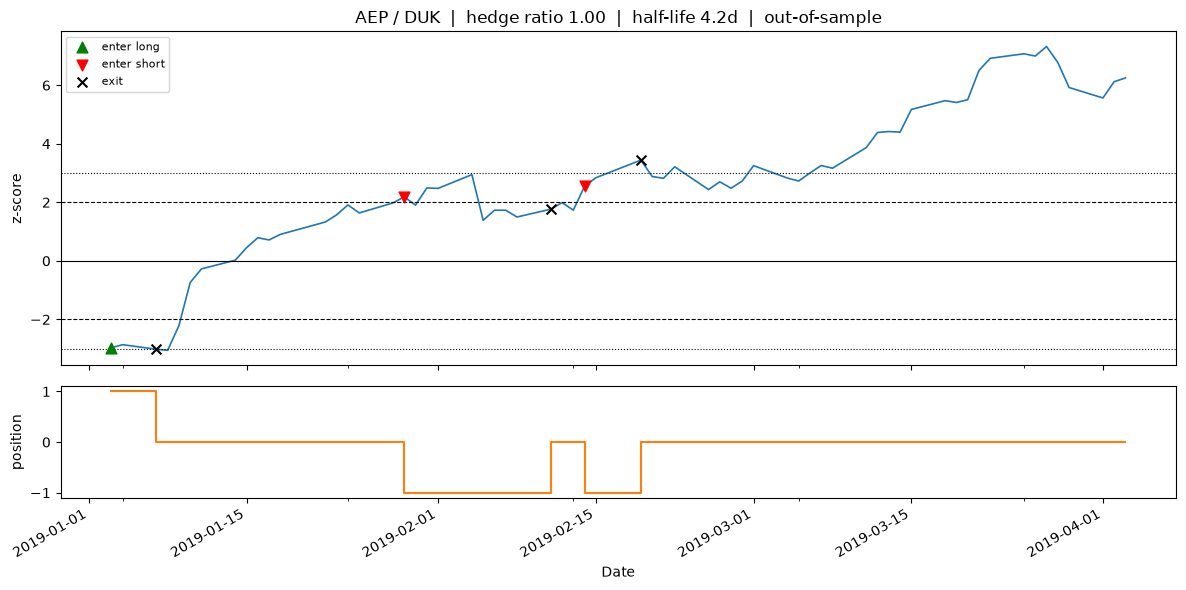

In [13]:
# One representative pair: z-score out-of-sample, with entry/exit bands and realised positions.
s = signals[0]
z, pos = s["z"], s["positions"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

z.plot(ax=ax1, color="C0", lw=1.2)
for lvl, style in [(0, "-"), (ENTRY_Z, "--"), (-ENTRY_Z, "--"), (STOP_Z, ":"), (-STOP_Z, ":")]:
    ax1.axhline(lvl, color="k", lw=0.8, ls=style)

prev = pos.shift(fill_value=0)
enter_long = (pos == 1) & (prev != 1)
enter_short = (pos == -1) & (prev != -1)
exits = (pos == 0) & (prev != 0)
ax1.scatter(z.index[enter_long], z[enter_long], marker="^", color="green", s=60, zorder=5, label="enter long")
ax1.scatter(z.index[enter_short], z[enter_short], marker="v", color="red", s=60, zorder=5, label="enter short")
ax1.scatter(z.index[exits], z[exits], marker="x", color="k", s=50, zorder=5, label="exit")
ax1.set_title(f"{s['a']} / {s['b']}  |  hedge ratio {s['hedge_ratio']:.2f}  |  "
              f"half-life {s['half_life']:.1f}d  |  out-of-sample")
ax1.set_ylabel("z-score")
ax1.legend(loc="upper left", fontsize=8)

pos.plot(ax=ax2, drawstyle="steps-post", color="C1")
ax2.set_ylabel("position")
ax2.set_yticks([-1, 0, 1])
ax2.set_xlabel("Date")
plt.tight_layout()
plt.show()

## Phase 4 — PnL engine

One function: daily target weights + prices → daily equity curve. Every later result runs through it.

- **Weights** are fractions of NAV as of each day's close; positive = long, negative = short. The engine requires them to be **dollar-neutral** (rows sum to zero) and raises otherwise — a broken neutrality constraint upstream should fail loudly, not show up as hidden beta.
- **Timing.** `held_t = w_{t-1}`: the target set at close *t−1* is the position during day *t*, earning `P_t / P_{t-1} − 1`. A signal never earns the return of the bar it was computed on.
- **Mark to market daily**, compounding: `NAV_t = NAV_{t-1} · (1 + gross_t − costs_t)`.
- **Costs.** On every change in held weights: `(COMMISSION_RATE + HALF_SPREAD) · Σ|Δw|` — both legs appear in the sum, so the half-spread is paid on each. Every day: borrow on the short leg, `Σ|w_short| · BORROW_RATE_ANNUAL / 252`. Turnover ignores intraday weight drift (weights are re-targeted daily), which is standard and immaterial at these sizes.
- **Sizing.** Per the spec, each pair is equal dollars long and short. The hedge ratio β shapes the *signal* (which spread we watch), not the *position size*.

In [14]:
def run_backtest(weights, prices,
                 commission=COMMISSION_RATE, half_spread=HALF_SPREAD,
                 borrow_annual=BORROW_RATE_ANNUAL):
    """Daily target weights (fraction of NAV, set at each close) + prices -> daily equity curve.

    Returns a DataFrame indexed like `prices` with columns:
      gross_ret, tc, borrow, net_ret, turnover, gross_exposure, gross_equity, equity
    """
    w = weights.reindex(index=prices.index, columns=prices.columns).fillna(0.0)

    net_exposure = w.sum(axis=1)
    if (net_exposure.abs() > 1e-8).any():
        worst = net_exposure.abs().idxmax()
        raise ValueError(f"weights are not dollar-neutral: net exposure {net_exposure[worst]:+.4f} on {worst.date()}")

    held = w.shift(1).fillna(0.0)
    rets = prices.pct_change().fillna(0.0)

    gross_ret = (held * rets).sum(axis=1)
    turnover = (held - held.shift(1).fillna(0.0)).abs().sum(axis=1)
    tc = turnover * (commission + half_spread)
    borrow = held.clip(upper=0.0).abs().sum(axis=1) * borrow_annual / TRADING_DAYS_PER_YEAR
    net_ret = gross_ret - tc - borrow

    return pd.DataFrame({
        "gross_ret": gross_ret,
        "tc": tc,
        "borrow": borrow,
        "net_ret": net_ret,
        "turnover": turnover,
        "gross_exposure": held.abs().sum(axis=1),
        "gross_equity": (1.0 + gross_ret).cumprod(),
        "equity": (1.0 + net_ret).cumprod(),
    })


In [15]:
# Synthetic check with a known answer. A: 100 -> 104 -> 107 -> 110, B: 100 -> 98 -> 96 -> 95.
# Long A / short B, 50% each, target set on day 0, closed on day 3. Day 4 is flat so the exit
# trade and its cost get booked. Expected numbers below are worked by hand, not via engine code.
idx = pd.date_range("2020-01-01", periods=5, freq="D")
px = pd.DataFrame({"A": [100, 104, 107, 110, 110],
                   "B": [100,  98,  96,  95,  95]}, index=idx, dtype=float)
wt = pd.DataFrame({"A": [0.5, 0.5, 0.5, 0.0, 0.0],
                   "B": [-0.5, -0.5, -0.5, 0.0, 0.0]}, index=idx)

res = run_backtest(wt, px)

# Gross daily returns of a 50/50 long-A short-B book, held on days 1-3 (targets from days 0-2).
g1 = 0.5 * (104 / 100 - 1) - 0.5 * (98 / 100 - 1)
g2 = 0.5 * (107 / 104 - 1) - 0.5 * (96 / 98 - 1)
g3 = 0.5 * (110 / 107 - 1) - 0.5 * (95 / 96 - 1)

per_unit = COMMISSION_RATE + HALF_SPREAD          # paid per unit of NAV traded, per leg
tc_entry = (0.5 + 0.5) * per_unit                 # day 1: both legs opened
tc_exit = (0.5 + 0.5) * per_unit                  # day 4: both legs closed
borrow_day = 0.5 * BORROW_RATE_ANNUAL / TRADING_DAYS_PER_YEAR  # short leg, each of days 1-3

expected_gross = (1 + g1) * (1 + g2) * (1 + g3)
expected_net = ((1 + g1 - tc_entry - borrow_day)
                * (1 + g2 - borrow_day)
                * (1 + g3 - borrow_day)
                * (1 - tc_exit))

assert np.isclose(res.gross_equity.iloc[-1], expected_gross, rtol=0, atol=1e-12)
assert np.isclose(res.equity.iloc[-1], expected_net, rtol=0, atol=1e-12)
assert np.isclose(res.tc.sum(), tc_entry + tc_exit, atol=1e-12)
assert np.isclose(res.borrow.sum(), 3 * borrow_day, atol=1e-12)
assert res.gross_ret.iloc[0] == 0 and res.tc.iloc[0] == 0, "nothing should happen on day 0"
assert res.gross_ret.iloc[4] == 0 and res.tc.iloc[4] == tc_exit, "day 4: flat prices, exit cost only"

# The dollar-neutrality guard must fire.
try:
    run_backtest(wt.assign(B=wt.B * 0.9), px)
    raise AssertionError("engine accepted a non-neutral book")
except ValueError:
    pass

print(f"gross PnL {expected_gross - 1:+.4%}   net PnL {expected_net - 1:+.4%}   "
      f"costs {tc_entry + tc_exit + 3 * borrow_day:.4%}")
print("PnL engine: all asserts pass")
res.round(6)


gross PnL +7.5658%   net PnL +7.3507%   costs 0.2030%
PnL engine: all asserts pass


,gross_ret,tc,borrow,net_ret,turnover,gross_exposure,gross_equity,equity
2020-01-01,0.000000,0.000,0.00000,0.000000,0.0,0.0,1.000000,1.000000
2020-01-02,0.030000,0.001,0.00001,0.028990,1.0,1.0,1.030000,1.028990
2020-01-03,0.024627,0.000,0.00001,0.024617,0.0,1.0,1.055366,1.054321
2020-01-04,0.019227,0.000,0.00001,0.019217,0.0,1.0,1.075658,1.074582
2020-01-05,0.000000,0.001,0.00000,-0.001000,1.0,0.0,1.075658,1.073507


AEP/DUK  gross -0.25%   net -0.86%   costs 0.613%   turnover 6.0x NAV


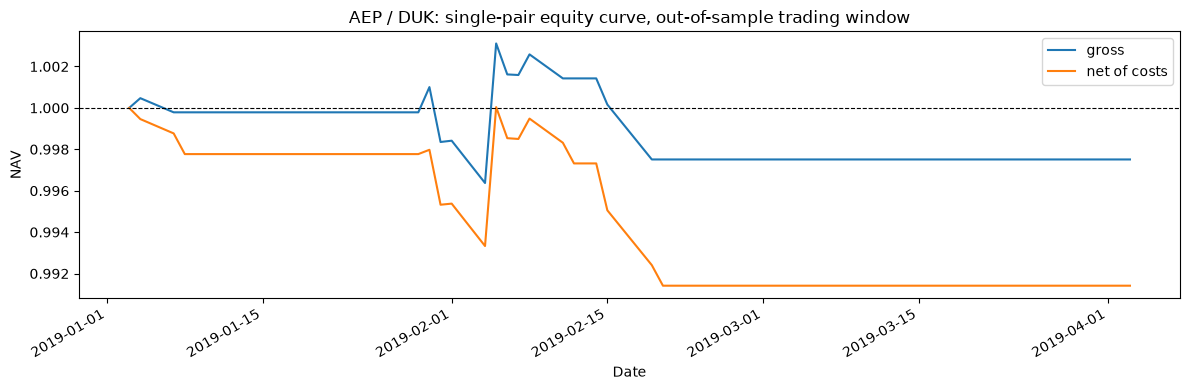

In [16]:
# Sanity check on real data: the O / SPG signal from Phase 3, equal-dollar legs, through the engine.
s = signals[0]
pair_w = pd.DataFrame({s["a"]: 0.5 * s["positions"], s["b"]: -0.5 * s["positions"]})
pair_res = run_backtest(pair_w, prices.loc[trade_idx, [s["a"], s["b"]]])

print(f"{s['a']}/{s['b']}  gross {pair_res.gross_equity.iloc[-1] - 1:+.2%}   "
      f"net {pair_res.equity.iloc[-1] - 1:+.2%}   costs {pair_res.tc.sum() + pair_res.borrow.sum():.3%}   "
      f"turnover {pair_res.turnover.sum():.1f}x NAV")

fig, ax = plt.subplots(figsize=(12, 4))
pair_res[["gross_equity", "equity"]].plot(ax=ax)
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_title(f"{s['a']} / {s['b']}: single-pair equity curve, out-of-sample trading window")
ax.set_ylabel("NAV")
ax.set_xlabel("Date")
ax.legend(["gross", "net of costs"])
plt.tight_layout()
plt.show()


## Phase 5 — Walk-forward loop

Roll through the full history in non-overlapping `TRADING_WINDOW` steps. Each step:

1. **Form** on the trailing `FORMATION_WINDOW` days: Engle-Granger on every within-sector pair (Phase 2), then z-score moments and half-life for each survivor (Phase 3). Everything from the previous cycle — pairs, hedge ratios, moments — is thrown away.
2. **Cap** the book at `MAX_CONCURRENT_POSITIONS` pairs, taken in order of ADF p-value (strongest cointegration first). This is decided on formation data only, so it cannot leak.
3. **Signal** on the next `TRADING_WINDOW` days using the frozen parameters.
4. **Book** = sum of pair positions: each active pair is `+PAIR_LEG_WEIGHT` on A and `−PAIR_LEG_WEIGHT` on B (equal dollars per leg). A stock in several pairs simply accumulates. Rows net to zero by construction.

Concatenating the trading windows gives one continuous out-of-sample weight series; positions still open when a window ends are closed at the start of the next one (the new pair set replaces them, and the engine books the exit costs). One `run_backtest` call over the whole thing gives the equity curve.

In [17]:
def book_weights(sigs, trade_idx, columns, leg_weight=PAIR_LEG_WEIGHT):
    """Sum pair positions into per-stock target weights. Rows net to zero by construction."""
    w = pd.DataFrame(0.0, index=trade_idx, columns=columns)
    for s in sigs:
        w[s["a"]] += leg_weight * s["positions"]
        w[s["b"]] -= leg_weight * s["positions"]
    return w


def walk_forward(log_px, ticker_sector,
                 formation=FORMATION_WINDOW, trading=TRADING_WINDOW,
                 max_positions=MAX_CONCURRENT_POSITIONS, leg_weight=PAIR_LEG_WEIGHT,
                 significance=ADF_SIGNIFICANCE, verbose=True):
    """Returns (weights, windows, signals_by_window).

    weights:            out-of-sample target weights, one row per trading day after the first formation window
    windows:            one row per step with pair counts and dates
    signals_by_window:  the Phase 3 signal dicts actually traded in each window (for later inspection)
    """
    idx = log_px.index
    weights, windows, signals_by_window = [], [], []

    for k, start in enumerate(range(formation, len(idx), trading)):
        form_idx = idx[start - formation:start]
        trade_idx = idx[start:start + trading]

        selected, _ = form_pairs(log_px.loc[form_idx], ticker_sector, significance)
        sigs = [build_pair_signal(log_px, row, form_idx, trade_idx) for row in selected.itertuples()]
        sigs = [s for s in sigs if s is not None][:max_positions]

        weights.append(book_weights(sigs, trade_idx, log_px.columns, leg_weight))
        signals_by_window.append(sigs)
        windows.append(dict(window=k, form_start=form_idx[0], trade_start=trade_idx[0], trade_end=trade_idx[-1],
                            n_cointegrated=len(selected), n_traded=len(sigs)))
        if verbose and k % 10 == 0:
            print(f"window {k:3d}  trade {trade_idx[0].date()} -> {trade_idx[-1].date()}  "
                  f"cointegrated {len(selected):3d}  traded {len(sigs):2d}")

    return pd.concat(weights), pd.DataFrame(windows).set_index("window"), signals_by_window


In [18]:
import time

t0 = time.time()
wf_weights, wf_windows, wf_signals = walk_forward(log_prices, TICKER_SECTOR)
print(f"\n{len(wf_windows)} windows in {time.time() - t0:.0f}s")

oos_prices = prices.loc[wf_weights.index]
wf = run_backtest(wf_weights, oos_prices)

n_open = (wf_weights.abs().sum(axis=1) / (2 * PAIR_LEG_WEIGHT)).round().astype(int)
print(f"Out-of-sample: {wf.index[0].date()} -> {wf.index[-1].date()} ({len(wf)} days)")
print(f"Pairs traded per window: mean {wf_windows.n_traded.mean():.1f}, min {wf_windows.n_traded.min()}, max {wf_windows.n_traded.max()}")
print(f"Open pairs per day:      mean {n_open.mean():.1f}, max {n_open.max()}")
print(f"Final NAV: gross {wf.gross_equity.iloc[-1]:.3f}   net {wf.equity.iloc[-1]:.3f}")
wf_windows.head()


window   0  trade 2019-01-03 -> 2019-04-03  cointegrated 122  traded 20


window  10  trade 2021-07-06 -> 2021-10-01  cointegrated 171  traded 20


window  20  trade 2024-01-05 -> 2024-04-05  cointegrated  92  traded 20


window  30  trade 2026-07-14 -> 2026-09-14  cointegrated 102  traded 20

31 windows in 46s
Out-of-sample: 2019-01-03 -> 2026-09-14 (1934 days)
Pairs traded per window: mean 20.0, min 20, max 20
Open pairs per day:      mean 3.6, max 11
Final NAV: gross 0.943   net 0.797


,form_start,trade_start,trade_end,n_cointegrated,n_traded
window,,,,,
0,2018-01-02,2019-01-03,2019-04-03,122,20
1,2018-04-04,2019-04-04,2019-07-03,94,20
2,2018-07-03,2019-07-05,2019-10-02,86,20
3,2018-10-02,2019-10-03,2020-01-02,133,20
4,2019-01-03,2020-01-03,2020-04-02,118,20


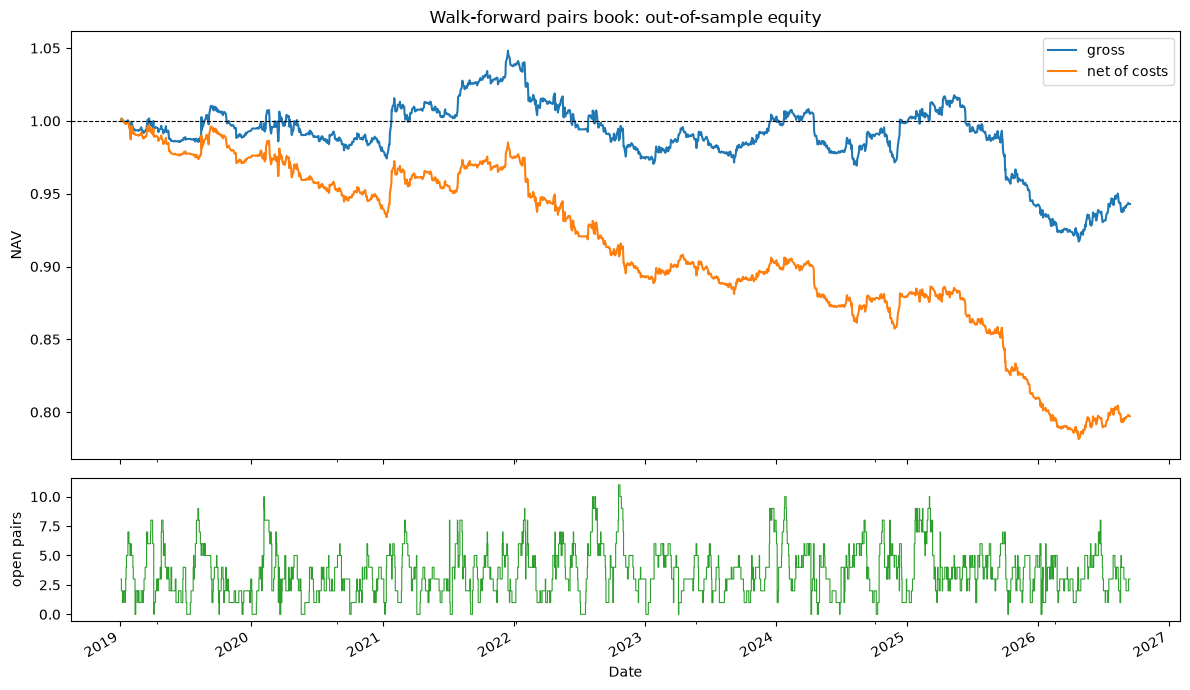

In [19]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

wf[["gross_equity", "equity"]].plot(ax=ax1)
ax1.axhline(1.0, color="k", lw=0.8, ls="--")
ax1.set_title("Walk-forward pairs book: out-of-sample equity")
ax1.set_ylabel("NAV")
ax1.legend(["gross", "net of costs"])

n_open.plot(ax=ax2, drawstyle="steps-post", color="C2", lw=0.8)
ax2.set_ylabel("open pairs")
ax2.set_xlabel("Date")
plt.tight_layout()
plt.show()


**First look** (numbers from the full 2010–2026 run; the shorter 2018+ sample tells the same story). The book loses money gross of costs (NAV 0.78 over 15 years) and costs roughly double the damage (0.55). Before accepting that, the usual bug checks were run outside the notebook: removing the one-day lag makes it *worse* (a same-bar entry earns the move that triggered it), a two-day lag gives the same answer as one day, and sign-flipping the weights yields +26% gross — so timing is clean and the signal is mildly anti-predictive rather than mis-wired.

The trade log explains it: ~1,800 trades, 40% hit rate, and **half of all exits are the ±3 z-stop**; only 7% revert to zero. Out of sample the spread's σ is close to the formation estimate (median 1.07), but its *mean* sits 1.5σ away from the formation mean — the spread doesn't oscillate around the old level, it drifts to a new one. Entered at |z| ≈ 2.3, a drifting spread hits 3 long before it hits 0. In-sample cointegration in the 20 strongest pairs mostly does not persist into the next quarter. Phase 6 quantifies this by year; Phase 9 checks whether any threshold / formation length / cost combination survives.

## Phase 6 — Pairs strategy results

Net and gross Sharpe, max drawdown, turnover, hit rate, by calendar year, against buy-and-hold SPY over the same days. Sharpe uses a zero risk-free rate. Turnover is `Σ|Δw|` summed over the year, in multiples of NAV, counting both legs. Hit rate is the share of closed pair trades with positive gross PnL, bucketed by entry date. SPY is a reference for what the same capital did unhedged — it is not the benchmark a market-neutral book should beat, and its Sharpe is included only for scale.

In [20]:
spy = load_prices(["SPY"], DATA_START, DATA_END, DATA_DIR / f"spy_{DATA_START}.pkl")["SPY"].reindex(prices.index).ffill()
spy_ret = spy.pct_change().fillna(0.0)


In [21]:
def max_drawdown(equity):
    return (equity / equity.cummax() - 1.0).min()


def perf_stats(ret):
    """Annualised stats for a daily return series (rf = 0)."""
    eq = (1.0 + ret).cumprod()
    years = len(ret) / TRADING_DAYS_PER_YEAR
    vol = ret.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    return pd.Series({
        "return": eq.iloc[-1] ** (1.0 / years) - 1.0 if years > 0 else np.nan,
        "vol": vol,
        "sharpe": ret.mean() / ret.std() * np.sqrt(TRADING_DAYS_PER_YEAR) if ret.std() > 0 else np.nan,
        "max_dd": max_drawdown(eq),
    })


def trade_log(signals_by_window, px, stop=STOP_Z, max_half_lives=MAX_HALF_LIVES_HELD):
    """One row per closed pair trade: dates, direction, days held, exit reason, gross return per $1 leg."""
    rows = []
    for k, sigs in enumerate(signals_by_window):
        for s in sigs:
            pos, z = s["positions"], s["z"]
            rets = px.loc[pos.index, [s["a"], s["b"]]].pct_change().fillna(0.0)
            pair_ret = pos.shift(1).fillna(0.0) * (rets[s["a"]] - rets[s["b"]])
            prev = pos.shift(fill_value=0)
            for entry in pos.index[(pos != 0) & (prev != pos)]:
                side = int(pos.loc[entry])
                after = pos.loc[entry:]
                changed = after != side          # a flip straight to the other side also closes this trade
                exit_ = changed.idxmax() if changed.any() else after.index[-1]
                days = after.index.get_loc(exit_)
                z_exit = z.loc[exit_]
                if not changed.any():
                    reason = "end-of-window"
                elif (side == 1 and z_exit >= EXIT_Z) or (side == -1 and z_exit <= EXIT_Z):
                    reason = "revert"
                elif abs(z_exit) >= stop:
                    reason = "z-stop"
                else:
                    reason = "time-stop"
                # held days are entry+1 .. exit (held_t = pos_{t-1}), so skip the entry bar's return
                rows.append(dict(window=k, a=s["a"], b=s["b"], side=side,
                                 entry=entry, exit=exit_, days=days, reason=reason,
                                 z_entry=z.loc[entry], z_exit=z_exit,
                                 ret=pair_ret.loc[entry:exit_].iloc[1:].sum()))
    return pd.DataFrame(rows)


def yearly_report(bt, trades, spy_ret):
    """Calendar-year table: strategy gross & net vs SPY, plus a full-period row."""
    groups = list(bt.groupby(bt.index.year)) + [("all", bt)]
    rows = []
    for label, chunk in groups:
        t = trades if label == "all" else trades[trades.entry.dt.year == label]
        g, n, s = perf_stats(chunk.gross_ret), perf_stats(chunk.net_ret), perf_stats(spy_ret.loc[chunk.index])
        rows.append(pd.Series({
            ("gross", "return"): g["return"], ("gross", "sharpe"): g["sharpe"],
            ("net", "return"): n["return"], ("net", "sharpe"): n["sharpe"], ("net", "max_dd"): n["max_dd"],
            ("net", "vol"): n["vol"],
            ("book", "turnover"): chunk.turnover.sum() * (TRADING_DAYS_PER_YEAR / len(chunk)),
            ("book", "avg_exposure"): chunk.gross_exposure.mean(),
            ("book", "trades"): len(t), ("book", "hit_rate"): (t.ret > 0).mean() if len(t) else np.nan,
            ("SPY", "return"): s["return"], ("SPY", "sharpe"): s["sharpe"], ("SPY", "max_dd"): s["max_dd"],
        }, name=label))
    return pd.DataFrame(rows)


In [22]:
trades = trade_log(wf_signals, prices)
report = yearly_report(wf, trades, spy_ret)

fmt = {c: "{:+.1%}" for c in report.columns if c[1] in ("return", "max_dd")}
fmt.update({c: "{:+.2f}" for c in report.columns if c[1] == "sharpe"})
fmt.update({("net", "vol"): "{:.1%}", ("book", "turnover"): "{:.1f}x", ("book", "avg_exposure"): "{:.0%}",
            ("book", "trades"): "{:.0f}", ("book", "hit_rate"): "{:.0%}"})
display(report.style.format(fmt, na_rep="-"))

full = report.loc["all"]
print(f"Full period {wf.index[0].date()} -> {wf.index[-1].date()}")
print(f"  net Sharpe {full[('net','sharpe')]:+.2f}   gross Sharpe {full[('gross','sharpe')]:+.2f}   "
      f"SPY Sharpe {full[('SPY','sharpe')]:+.2f}")
print(f"  net max drawdown {full[('net','max_dd')]:+.1%}   annual turnover {full[('book','turnover')]:.1f}x NAV   "
      f"hit rate {full[('book','hit_rate')]:.0%} over {full[('book','trades')]:.0f} trades")
print(f"  costs: {(wf.tc.sum() + wf.borrow.sum()) / len(wf) * TRADING_DAYS_PER_YEAR:.2%} of NAV per year")
print("\nExit reasons:")
print(trades.groupby("reason").ret.agg(count="count", mean_bps=lambda r: r.mean() * 1e4, hit=lambda r: (r > 0).mean())
      .round({"mean_bps": 1, "hit": 2}).to_string())


Full period 2019-01-03 -> 2026-09-14
  net Sharpe -0.91   gross Sharpe -0.23   SPY Sharpe +0.92
  net max drawdown -22.0%   annual turnover 21.0x NAV   hit rate 41% over 830 trades
  costs: 2.19% of NAV per year

Exit reasons:
               count  mean_bps   hit
reason                              
end-of-window     90      36.2  0.56
revert            79     863.1  0.97
time-stop        246     217.8  0.70
z-stop           415    -330.6  0.10


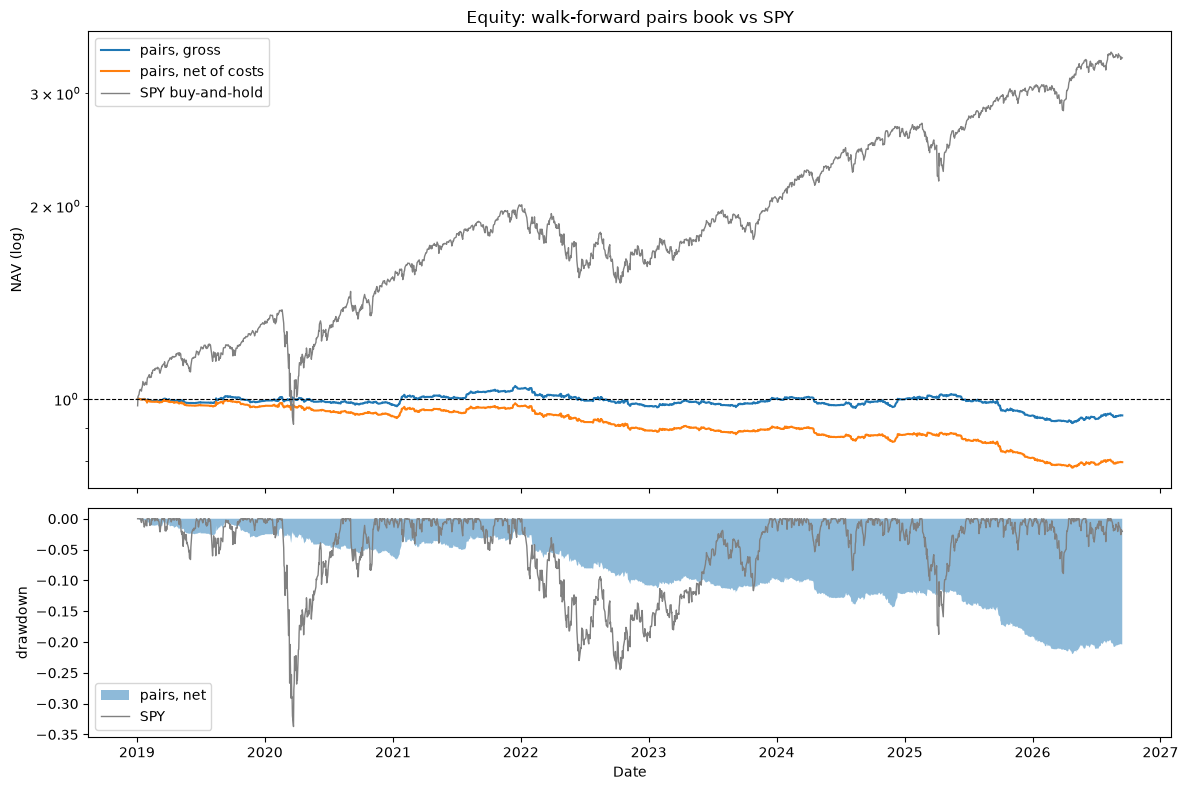

In [23]:
spy_eq = (1.0 + spy_ret.loc[wf.index]).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(wf.index, wf.gross_equity, label="pairs, gross")
ax1.plot(wf.index, wf.equity, label="pairs, net of costs")
ax1.plot(spy_eq.index, spy_eq, label="SPY buy-and-hold", color="0.5", lw=1)
ax1.axhline(1.0, color="k", lw=0.8, ls="--")
ax1.set_yscale("log")
ax1.set_ylabel("NAV (log)")
ax1.set_title("Equity: walk-forward pairs book vs SPY")
ax1.legend(loc="upper left")

ax2.fill_between(wf.index, wf.equity / wf.equity.cummax() - 1.0, 0, alpha=0.5, label="pairs, net")
ax2.plot(spy_eq.index, spy_eq / spy_eq.cummax() - 1.0, color="0.5", lw=1, label="SPY")
ax2.set_ylabel("drawdown")
ax2.set_xlabel("Date")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()


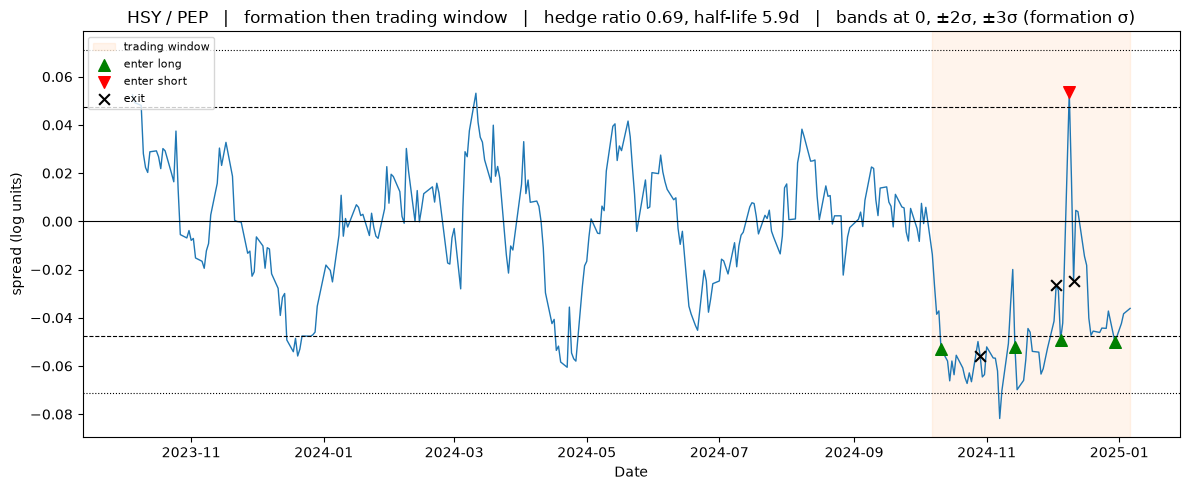

,side,entry,exit,days,reason,z_entry,z_exit,ret
615,1,2024-10-11,2024-10-29,12,time-stop,-2.231916,-2.353466,0.010213
616,1,2024-11-14,2024-12-03,12,time-stop,-2.193194,-1.108458,0.032595
617,1,2024-12-05,2024-12-09,2,revert,-2.074571,2.253140,0.107423
618,-1,2024-12-09,2024-12-11,2,revert,2.253140,-1.036289,0.070909
619,1,2024-12-30,2025-01-06,4,end-of-window,-2.109057,-1.522456,0.024838


In [24]:
# Representative pair: the (window, pair) with the most round trips, so entries and exits of every kind show.
counts = trades.groupby(["window", "a", "b"]).size()
k, a, b = counts.idxmax()
s = next(s for s in wf_signals[k] if s["a"] == a and s["b"] == b)

trade_idx = s["positions"].index
form_idx = log_prices.index[log_prices.index.get_loc(trade_idx[0]) - FORMATION_WINDOW:log_prices.index.get_loc(trade_idx[0])]
full_idx = form_idx.append(trade_idx)
spread = spread_from_params(log_prices.loc[full_idx], a, b, s["intercept"], s["hedge_ratio"])

pos = s["positions"]
prev = pos.shift(fill_value=0)
enter_long, enter_short, exits = (pos == 1) & (prev != 1), (pos == -1) & (prev != -1), (pos == 0) & (prev != 0)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(spread.index, spread, lw=1, color="C0")
ax.axvspan(trade_idx[0], trade_idx[-1], color="C1", alpha=0.08, label="trading window")
for n, ls in [(0, "-"), (ENTRY_Z, "--"), (-ENTRY_Z, "--"), (STOP_Z, ":"), (-STOP_Z, ":")]:
    ax.axhline(s["mu"] + n * s["sigma"], color="k", lw=0.8, ls=ls)
ax.scatter(spread.index[spread.index.isin(pos.index[enter_long])], spread[pos.index[enter_long]], marker="^", color="green", s=70, zorder=5, label="enter long")
ax.scatter(spread.index[spread.index.isin(pos.index[enter_short])], spread[pos.index[enter_short]], marker="v", color="red", s=70, zorder=5, label="enter short")
ax.scatter(spread.index[spread.index.isin(pos.index[exits])], spread[pos.index[exits]], marker="x", color="k", s=60, zorder=5, label="exit")
ax.set_title(f"{a} / {b}   |   formation then trading window   |   hedge ratio {s['hedge_ratio']:.2f}, "
             f"half-life {s['half_life']:.1f}d   |   bands at 0, ±{ENTRY_Z:.0f}σ, ±{STOP_Z:.0f}σ (formation σ)")
ax.set_ylabel("spread (log units)")
ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

trades[(trades.window == k) & (trades.a == a) & (trades.b == b)][["side", "entry", "exit", "days", "reason", "z_entry", "z_exit", "ret"]]
